# Prices at the snapshot: Kalshi and Polymarket

Overview of `contest_prices.csv`, `kalshi_prices.csv` and `polymarket_prices.csv`: each contest's price at its
snapshot and what the rules in `apply_rules.py` kept. Each section shows both platforms together, then each
platform on its own. Who won is not used anywhere here. Figures are saved to `figures/` as PNG and PDF.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

# Colours and text tokens (same as the cleaning overview)
GENERAL, PRIMARY = "#2a78d6", "#eb6834"
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
KINDS = {"General": GENERAL, "Primary": PRIMARY}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")


def value_grid(ax, axis="x"):
    ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def minutes_axis(ax, longest):
    """Log time axis in minutes, labelled 1 min ... 1 d."""
    ticks = [t for t in (1, 10, 60, 600, 1440, 1440 * 5) if t <= longest]
    names = {1: "1 min", 10: "10 min", 60: "1 h", 600: "10 h", 1440: "1 d", 1440 * 5: "5 d"}
    ax.set_xscale("log")
    ax.set_xticks(ticks, [names[t] for t in ticks])
    ax.minorticks_off()


def minutes_text(value):
    return f"{value / 60:.1f} h" if value >= 60 else f"{value:.0f} min"

## Load

In [2]:
contests = pd.read_csv("contest_prices.csv", dtype={"contest_id": str})
contests["kind"] = contests["kind"].str.capitalize()
contests["favourite"] = contests[["p_a", "p_b"]].max(axis=1)
kalshi_markets = pd.read_csv("kalshi_prices.csv")
poly_options = pd.read_csv("polymarket_prices.csv", dtype={"contest_id": str})
days = pd.read_csv("election_days.csv").set_index("key")

SHORT = {  # reason in contest_prices.csv -> label on the charts
    "kept": "Kept",
    "drop: favourite above 95% (scaled)": "Favourite above 95%",
    "drop: no quote within 10 cents and no trade in the hour before the snapshot": "Spread over 10¢, no trade in the last hour",
    "drop: prices of all options add up to more than 10 cents away from 1": "Prices more than 10¢ from adding up to 1",
    "drop: market opened after the snapshot": "Market opened after the vote",
    "drop: another candidate priced above 5%": "“Other” above 5%",
    "drop: neither candidate traded in the 24 hours before the snapshot": "No trade in the last 24 hours",
    "drop: no recorded price before the snapshot": "No recorded price",
    "drop: recorded price more than an hour old at the snapshot": "Recorded price over an hour old",
}
contests["outcome"] = contests["reason"].map(SHORT).fillna("API error")
kept = contests[contests["included"]]
PLATFORMS = {"Both platforms": contests, "Kalshi": contests[contests.platform == "Kalshi"],
             "Polymarket": contests[contests.platform == "Polymarket"]}
(contests.groupby(["platform", "included"]).size().unstack(fill_value=0)
 .rename(columns={True: "kept", False: "dropped"}).rename_axis(columns=None))

,dropped,kept
platform,,
Kalshi,198,169
Polymarket,140,84


## What the rules kept

In [3]:
def stacked_bars(table, title, name, order=None, xlabel="Contests"):
    table = table.reindex(columns=["General", "Primary"], fill_value=0)
    table = table.loc[order[::-1]] if order is not None else table.loc[table.sum(axis=1).sort_values().index]
    fig, ax = plt.subplots(figsize=(9, max(2.4, 0.42 * len(table) + 1.2)))
    y = np.arange(len(table))
    for kind, left in (("General", 0), ("Primary", table["General"])):
        ax.barh(y, table[kind], left=left, height=0.6, color=KINDS[kind], label=kind, edgecolor=SURFACE, linewidth=1.5)
    for i, (_, row) in enumerate(table.iterrows()):
        total = row.sum()
        text = f"{total}  ({row['General']} general, {row['Primary']} primary)" if row["Primary"] and row["General"] else str(total)
        ax.text(total + table.sum(axis=1).max() * 0.01, i, text, va="center", fontsize=9, color=INK_2)
    ax.set_yticks(y, table.index)
    ax.set_xlim(0, table.sum(axis=1).max() * 1.4)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(loc="lower right", ncols=2)
    value_grid(ax)
    fig.tight_layout()
    save(fig, name)


def rules(df, label, name):
    table = df.groupby(["outcome", "kind"]).size().unstack(fill_value=0)
    dropped = table.drop("Kept", errors="ignore")
    order = ["Kept"] + list(dropped.sum(axis=1).sort_values(ascending=False).index)
    kept_n = table.loc["Kept"].sum() if "Kept" in table.index else 0
    stacked_bars(table, f"{label} · {kept_n} of {len(df)} contests kept, and why the rest were dropped", name, order)

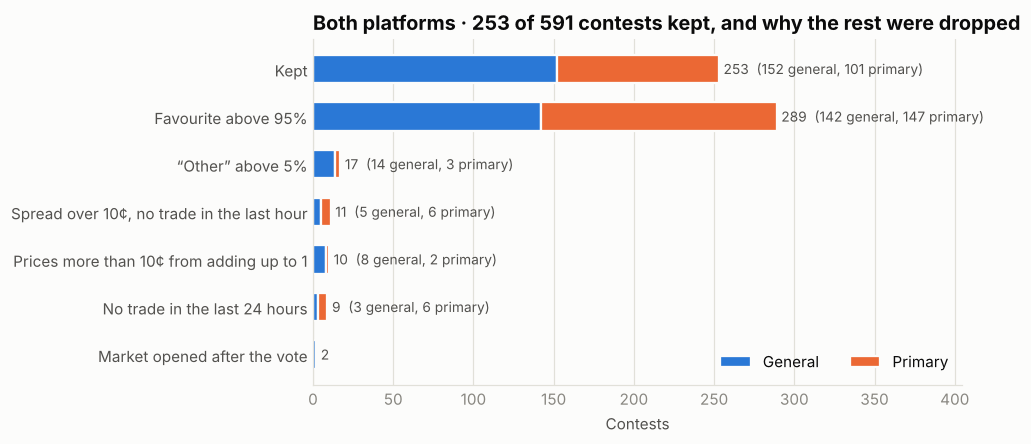

In [4]:
rules(PLATFORMS["Both platforms"], "Both platforms", "both_rules")

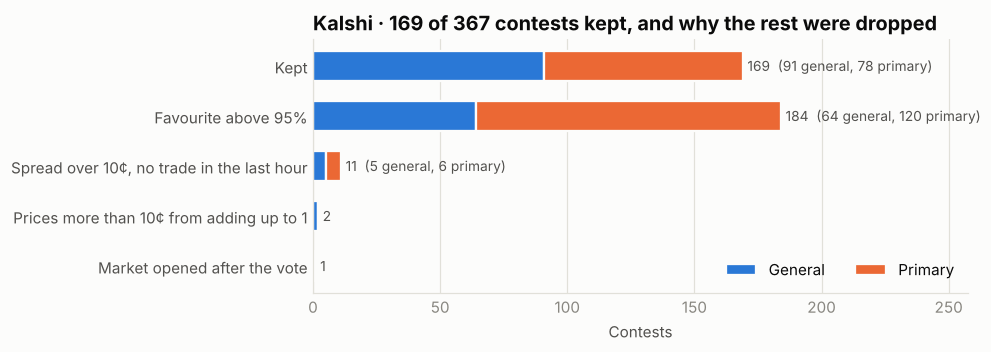

In [5]:
rules(PLATFORMS["Kalshi"], "Kalshi", "kalshi_rules")

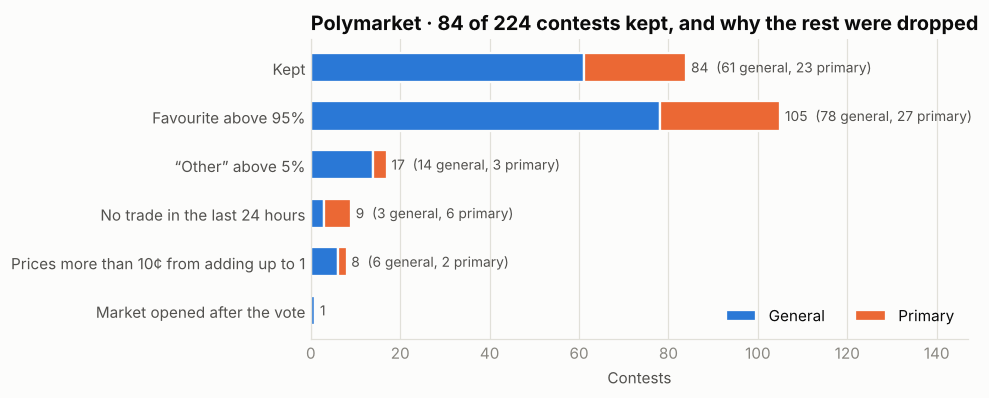

In [6]:
rules(PLATFORMS["Polymarket"], "Polymarket", "polymarket_rules")

## How sure the markets were

The favourite's price after the two candidate prices are scaled to sum to 1, for the contests that were kept.
Contests with a favourite above 95% were dropped and are counted in the title.

In [7]:
def favourite(df, label, name):
    mine = df[df["included"]]
    over = (df["outcome"] == "Favourite above 95%").sum()
    bins = np.arange(0.5, 0.95 + 1e-9, 0.025)
    fig, ax = plt.subplots(figsize=(9, 3.6))
    bottom = np.zeros(len(bins) - 1)
    for kind, colour in KINDS.items():
        counts, _ = np.histogram(mine.loc[mine["kind"] == kind, "favourite"], bins=bins)
        ax.bar(bins[:-1], counts, width=0.025, align="edge", bottom=bottom, color=colour, label=kind,
               edgecolor=SURFACE, linewidth=1.5)
        bottom += counts
    median = mine["favourite"].median()
    ax.axvline(median, color=INK_2, linewidth=1)
    ax.text(median + 0.004, bottom.max() * 1.02, f"median {median:.0%}", fontsize=9, color=INK_2)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlim(0.5, 0.95)
    ax.set_ylim(0, bottom.max() * 1.15)
    ax.set_xlabel("Favourite's scaled price at the snapshot")
    ax.set_ylabel("Contests")
    ax.set_title(f"{label} · {len(mine)} kept contests · {over} more had a favourite above 95%")
    ax.legend(loc="upper left", ncols=2)
    value_grid(ax, "y")
    fig.tight_layout()
    save(fig, name)

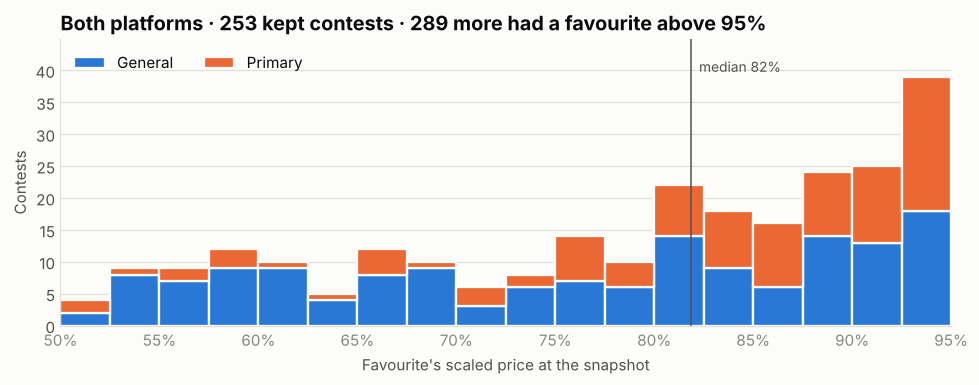

In [8]:
favourite(PLATFORMS["Both platforms"], "Both platforms", "both_favourite")

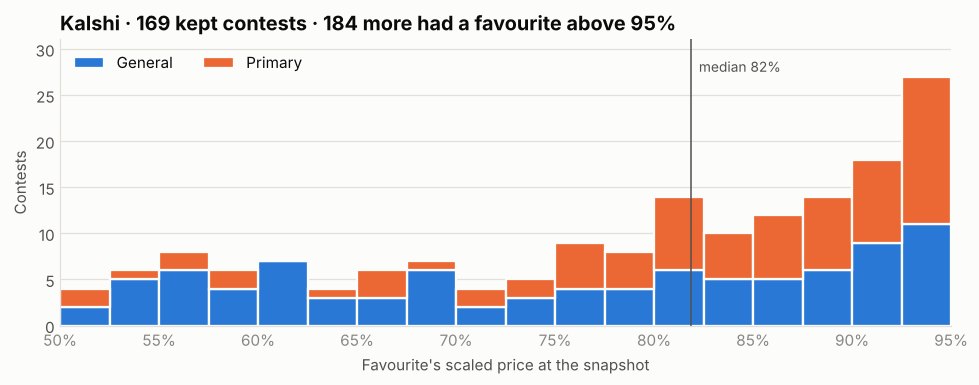

In [9]:
favourite(PLATFORMS["Kalshi"], "Kalshi", "kalshi_favourite")

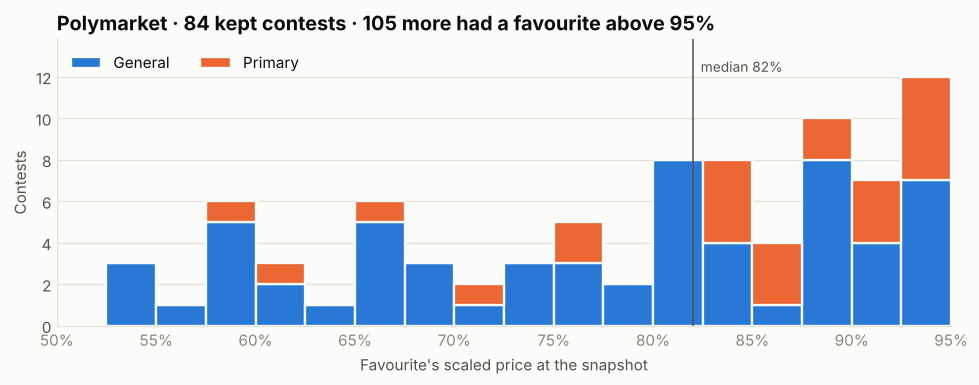

In [10]:
favourite(PLATFORMS["Polymarket"], "Polymarket", "polymarket_favourite")

## Election days

Kept contests by the day they were voted on. Contests on the same day share news and polling errors, which is why
the uncertainty check resamples whole election days.

In [11]:
def day_label(key):
    row = days.loc[key]
    when = pd.Timestamp(row["last_voting_day"]).strftime("%-d %b %Y")
    return f"{when} · {row['country']}"


def election_days(df, label, name, top=12):
    mine = df[df["included"]]
    table = mine.groupby(["election_key", "kind"]).size().unstack(fill_value=0).reindex(columns=["General", "Primary"], fill_value=0)
    table = table.loc[table.sum(axis=1).sort_values(ascending=False).index]
    shown, rest = table.iloc[:top], table.iloc[top:]
    shown.index = [day_label(key) for key in shown.index]
    order = list(shown.index)
    if len(rest):
        shown.loc[f"Other {len(rest)} days"] = rest.sum()
        order.append(f"Other {len(rest)} days")
    biggest = table.sum(axis=1).iloc[0] / len(mine)
    stacked_bars(shown, f"{label} · {len(mine)} kept contests on {len(table)} election days · "
                        f"the biggest day holds {biggest:.0%}", name, order)

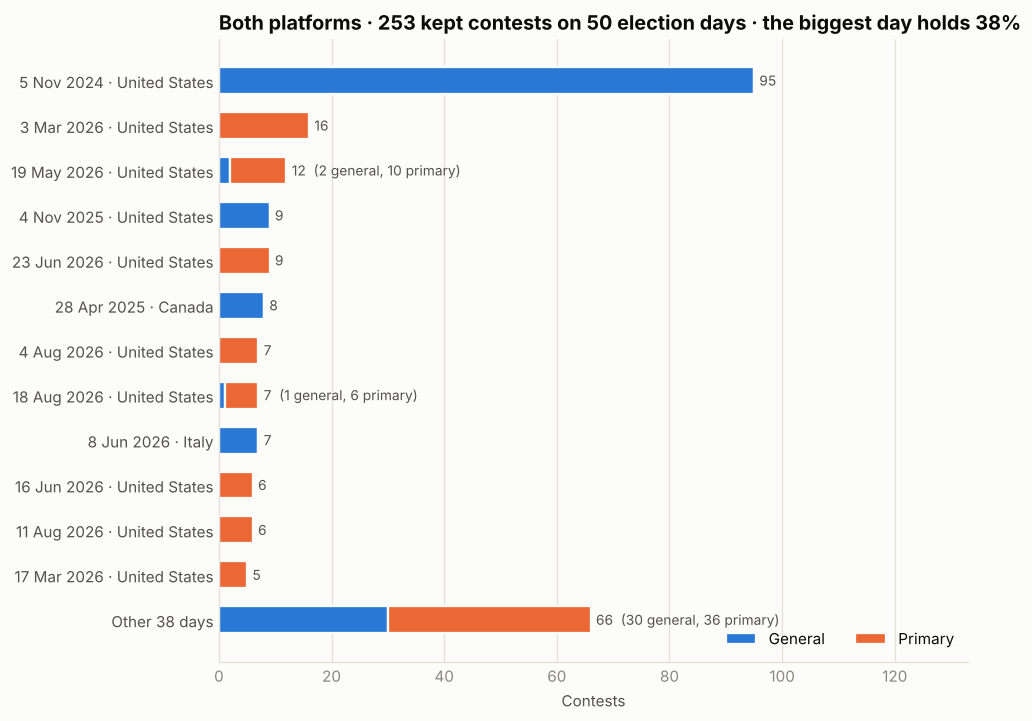

In [12]:
election_days(PLATFORMS["Both platforms"], "Both platforms", "both_election_days")

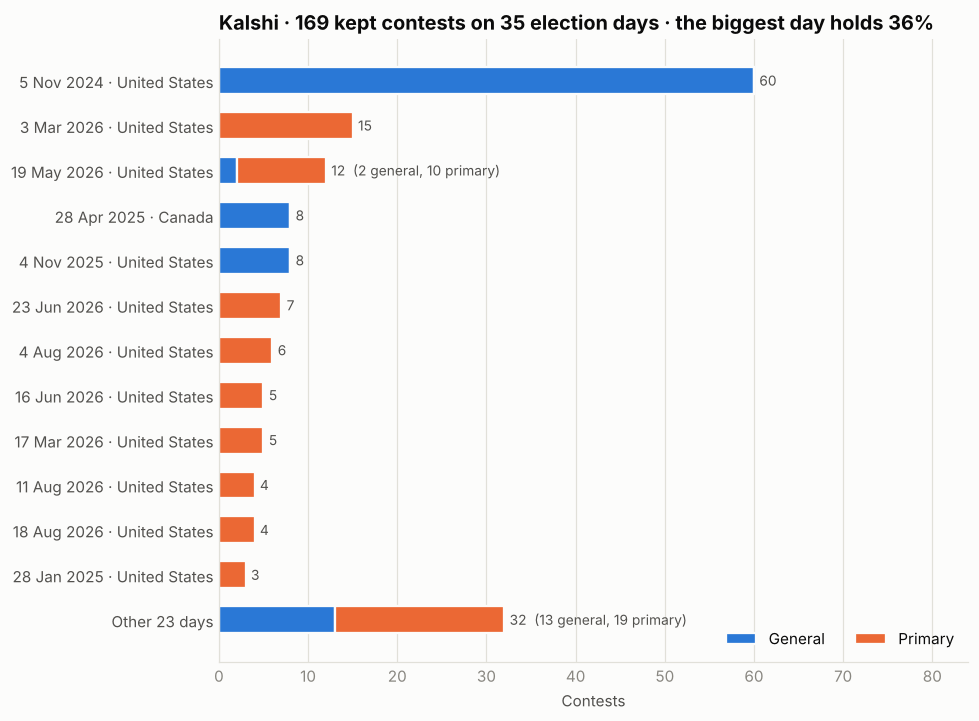

In [13]:
election_days(PLATFORMS["Kalshi"], "Kalshi", "kalshi_election_days")

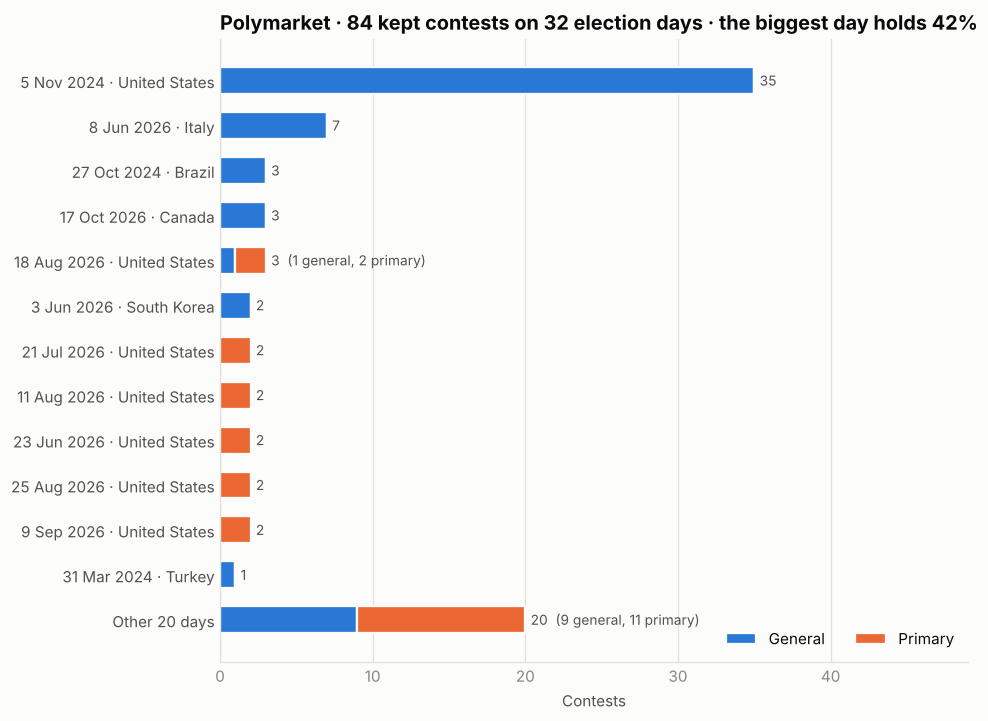

In [14]:
election_days(PLATFORMS["Polymarket"], "Polymarket", "polymarket_election_days")

## Were the prices fresh?

The two candidate prices (plus "Other", where it has a recorded price) should add up to about 1. Contests that
reached this check are shown; those outside the shaded band were dropped.

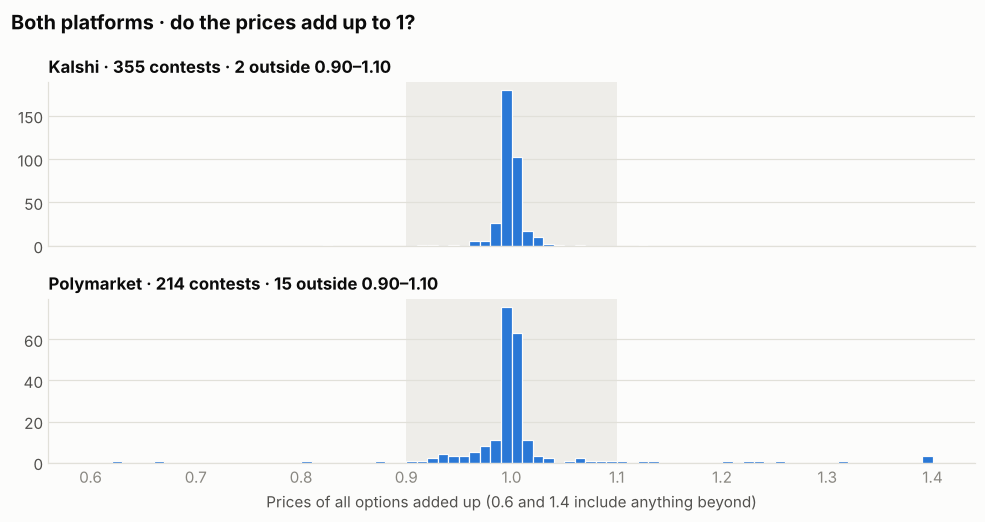

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(9, 4.8), sharex=True)
bins = np.arange(0.6, 1.4 + 1e-9, 0.01)
for ax, platform in zip(axes, ["Kalshi", "Polymarket"]):
    values = contests.loc[contests["platform"] == platform, "total"].dropna()
    ax.axvspan(0.9, 1.1, color=GRID, alpha=0.5, linewidth=0)
    ax.hist(values.clip(0.6, 1.4 - 1e-9), bins=bins, color=GENERAL, edgecolor=SURFACE, linewidth=0.8)
    outside = ((values - 1).abs() > 0.1 + 1e-9).sum()
    ax.set_title(f"{platform} · {len(values)} contests · {outside} outside 0.90–1.10", fontsize=11)
    value_grid(ax, "y")
axes[1].set_xlabel("Prices of all options added up (0.6 and 1.4 include anything beyond)")
fig.suptitle("Both platforms · do the prices add up to 1?", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "both_totals")

Kalshi: the gap between the best bid and ask, how long the order book had been unchanged, and the time since the
last trade, for every candidate market.

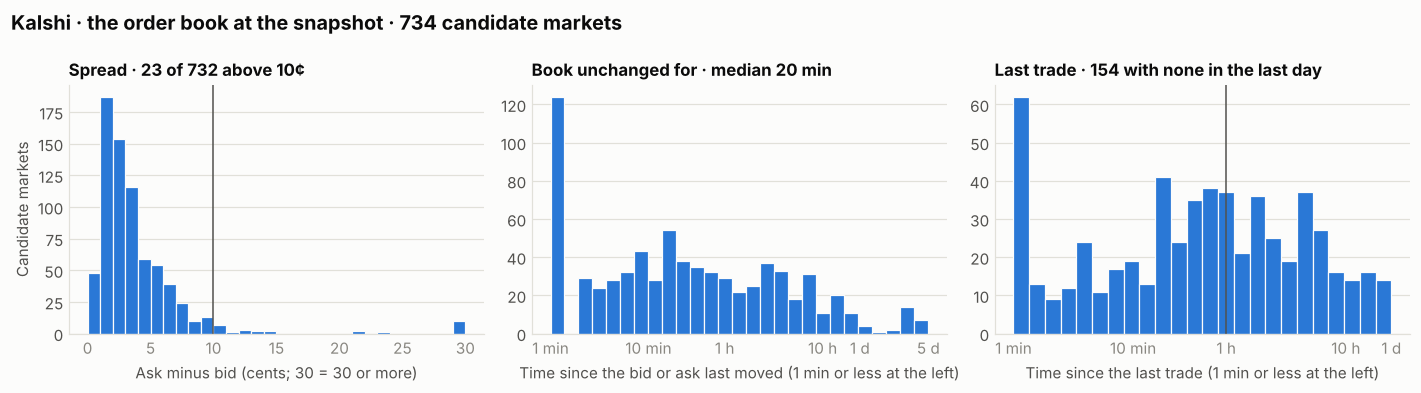

In [16]:
k = kalshi_markets.copy()
k["spread"] = (k["yes_ask"] - k["yes_bid"]) * 100
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

ax = axes[0]
ax.hist(k["spread"].dropna().clip(upper=30), bins=np.arange(0, 31, 1), color=GENERAL, edgecolor=SURFACE, linewidth=0.8)
ax.axvline(10, color=INK_2, linewidth=1)
wide = (k["spread"] > 10 + 1e-6).sum()
ax.set_title(f"Spread · {wide} of {k['spread'].notna().sum()} above 10¢", fontsize=11)
ax.set_xlabel("Ask minus bid (cents; 30 = 30 or more)")

ax = axes[1]
ax.hist(k["quote_age_minutes"].dropna().clip(1, 1440 * 5), bins=np.logspace(0, np.log10(1440 * 5), 28),
        color=GENERAL, edgecolor=SURFACE, linewidth=0.8)
minutes_axis(ax, 1440 * 5)
ax.set_title(f"Book unchanged for · median {minutes_text(k['quote_age_minutes'].median())}", fontsize=11)
ax.set_xlabel("Time since the bid or ask last moved (1 min or less at the left)")

ax = axes[2]
ax.hist(k["minutes_since_trade"].dropna().clip(1, 1440), bins=np.logspace(0, np.log10(1440), 25),
        color=GENERAL, edgecolor=SURFACE, linewidth=0.8)
ax.axvline(60, color=INK_2, linewidth=1)
minutes_axis(ax, 1440)
ax.set_title(f"Last trade · {k['minutes_since_trade'].isna().sum()} with none in the last day", fontsize=11)
ax.set_xlabel("Time since the last trade (1 min or less at the left)")

for ax in axes:
    value_grid(ax, "y")
axes[0].set_ylabel("Candidate markets")
fig.suptitle(f"Kalshi · the order book at the snapshot · {len(k)} candidate markets", x=0.01, ha="left",
             fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "kalshi_freshness")

Polymarket: the time since either candidate last traded (the 24-hour rule), and the price of "Other" where the
contest has one. Polymarket's history has no order book, so there is no spread to show.

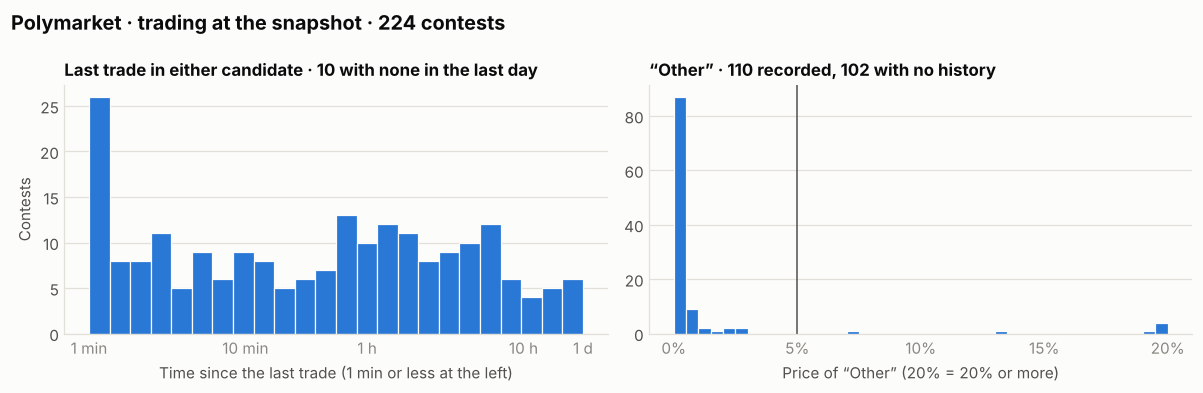

In [17]:
candidates = poly_options[poly_options["role"] == "candidate"]
last_trade = candidates.groupby("contest_id")["minutes_since_trade"].min()
other = poly_options.loc[poly_options["role"] == "basket", "price"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
ax.hist(last_trade.dropna().clip(1, 1440), bins=np.logspace(0, np.log10(1440), 25), color=GENERAL,
        edgecolor=SURFACE, linewidth=0.8)
minutes_axis(ax, 1440)
ax.set_title(f"Last trade in either candidate · {last_trade.isna().sum()} with none in the last day", fontsize=11)
ax.set_xlabel("Time since the last trade (1 min or less at the left)")
ax.set_ylabel("Contests")

ax = axes[1]
ax.hist(other.dropna().clip(upper=0.2 - 1e-9), bins=np.arange(0, 0.2001, 0.005), color=GENERAL, edgecolor=SURFACE, linewidth=0.8)
ax.axvline(0.05, color=INK_2, linewidth=1)
ax.set_xticks([0, 0.05, 0.1, 0.15, 0.2], ["0%", "5%", "10%", "15%", "20%"])
ax.set_title(f"“Other” · {other.notna().sum()} recorded, {other.isna().sum()} with no history", fontsize=11)
ax.set_xlabel("Price of “Other” (20% = 20% or more)")

for ax in axes:
    value_grid(ax, "y")
fig.suptitle(f"Polymarket · trading at the snapshot · {candidates['contest_id'].nunique()} contests",
             x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "polymarket_freshness")

## The same contest on both platforms

Contests listed on both platforms, matched by election day, state and the two candidates' surnames. Each dot is one
candidate's scaled price on Kalshi against Polymarket at the same snapshot.

30 of 86 pairs are kept on both platforms; largest gap 18.0 points (PA-07 election: Wild (D) vs. Mackenzie (R))


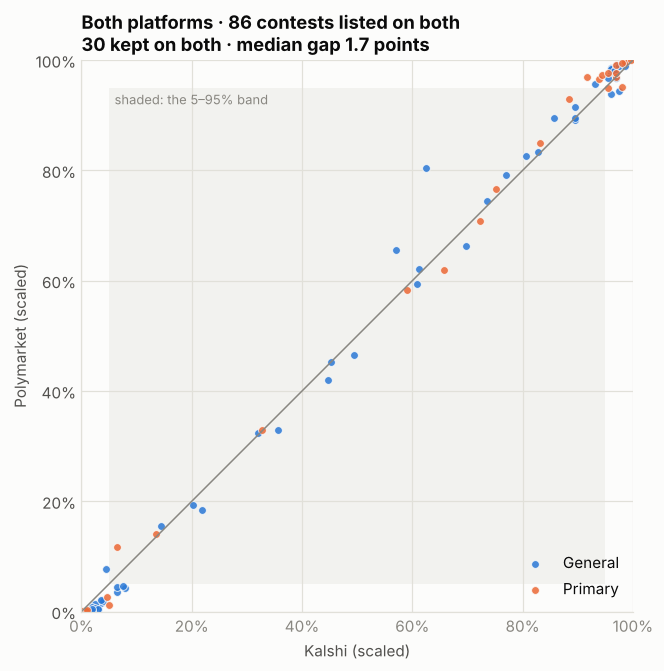

In [18]:
def surname(name):
    name = re.sub(r"\(.*?\)", "", str(name)).strip().lower()
    return name.split()[-1] if name else ""


both = contests.dropna(subset=["p_a"]).copy()
both = both[~both["title"].str.contains("Congressional district", case=False)]  # district-level presidential markets
both["names"] = both.apply(lambda r: frozenset({surname(r.candidate_a), surname(r.candidate_b)}), axis=1)
both["state"] = both["state"].fillna("")
pairs = both[both.platform == "Kalshi"].merge(both[both.platform == "Polymarket"],
                                               on=["election_key", "state", "names"], suffixes=("_k", "_p"))
assert not pairs["contest_id_k"].duplicated().any() and not pairs["contest_id_p"].duplicated().any()
same_order = pairs.apply(lambda r: surname(r.candidate_a_k) == surname(r.candidate_a_p), axis=1)
pairs["kalshi"] = pairs["p_a_k"]
pairs["polymarket"] = np.where(same_order, pairs["p_a_p"], pairs["p_b_p"])
pairs["both_kept"] = pairs["included_k"] & pairs["included_p"]
gap = (pairs["kalshi"] - pairs["polymarket"]).abs()

fig, ax = plt.subplots(figsize=(6.2, 6.2))
ax.add_patch(plt.Rectangle((0.05, 0.05), 0.9, 0.9, color=GRID, alpha=0.35, linewidth=0))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1)
for kind, colour in KINDS.items():
    mine = pairs[pairs["kind_k"] == kind]
    ax.scatter(mine["kalshi"], mine["polymarket"], s=26, color=colour, label=kind, alpha=0.85, edgecolor=SURFACE, linewidth=0.6)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Kalshi (scaled)"); ax.set_ylabel("Polymarket (scaled)")
ax.set_title(f"Both platforms · {len(pairs)} contests listed on both\n{pairs['both_kept'].sum()} kept on both · "
             f"median gap {gap.median() * 100:.1f} points", fontsize=12)
ax.text(0.06, 0.92, "shaded: the 5–95% band", fontsize=8.5, color=MUTED)
ax.legend(loc="lower right")
value_grid(ax, "both")
fig.tight_layout()
save(fig, "both_same_contest")
print(f"{pairs['both_kept'].sum()} of {len(pairs)} pairs are kept on both platforms; "
      f"largest gap {gap.max() * 100:.1f} points ({pairs.loc[gap.idxmax(), 'title_p']})")

## Table

In [19]:
table = (contests.groupby(["platform", "kind"])
         .agg(contests=("contest_id", "size"), kept=("included", "sum"),
              median_favourite_kept=("favourite", lambda s: s[contests.loc[s.index, "included"]].median()),
              election_days_kept=("election_key", lambda s: s[contests.loc[s.index, "included"]].nunique()))
         .round(3))
table.to_csv(FIGURES / "summary.csv")
table

contests  kept  median_favourite_kept  election_days_kept
platform   kind                                                              
Kalshi     General       163    91                  0.781                  15
           Primary       204    78                  0.855                  21
Polymarket General       163    61                  0.805                  16
           Primary        61    23                  0.865                  17